# 04 — Sensibilidade da definição do alvo (Etapa B)

**Problema.** Com o alvo atual (EBIT / despesa financeira < 1 em t+1 e t+2), 41% das linhas já estão em distress em t, e de 27% a 60% das empresas por ano têm cobertura menor que 1. Isso é muito acima dos cerca de 15–17% de empresas "zumbi" da literatura (BIS; Granzotto et al., 2025). A despesa financeira do Economatica é **bruta**: inclui variação cambial e monetária e, desde 2019, os juros de arrendamento do IFRS 16. Por isso o alvo fica largo demais.

Este notebook compara quatro definições **antes de qualquer modelo**. Nada aqui usa o desempenho de modelo.

## Critério de escolha (definido antes de olhar os resultados)

Preferir a definição que:
1. tenha **prevalência anual** de cobertura < 1 **mais próxima de 15–20%**;
2. **ainda sinalize a maioria dos eventos reais de crédito** em t−1 ou t−2;
3. tenha **eventos suficientes no treino**, idealmente **pelo menos 10 por parâmetro** da logística prevista (13 parâmetros: 7 índices e flags, a Selic e 5 dummies de macrossetor).

**O desempenho de modelo não é usado para escolher.** Escolher o alvo pelo que o modelo acerta melhor seria ajustar a pergunta à resposta.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config as cfg, dados, alvo, style

style.aplicar()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 220)
pd.set_option('display.float_format', lambda x: style.num_br(x, 3))

ea = pd.read_parquet(cfg.DATA_PROCESSED / 'base_empresa_ano.parquet')
print('Base empresa-ano:', ea.shape)

Base empresa-ano: (3633, 58)


## 1. As quatro definições

| | cobertura | distress exigido | t vai até |
|---|---|---|---|
| **A** (atual) | EBIT / desp. fin. < 1 | t+1 e t+2 | 2023 |
| **B** | EBITDA / desp. fin. < 1 | t+1 e t+2 | 2023 |
| **C** | EBIT / desp. fin. < 1 | t+1, t+2 e t+3 | 2022 |
| **D** | EBITDA / desp. fin. < 1 | t+1, t+2 e t+3 | 2022 |

Regras comuns às quatro:
- despesa financeira ≤ 0 → **não classificável**;
- amostra em risco = **fora de distress em t pela mesma definição** e alvo observado;
- **anos pré-IPO (`pre_registro`) fora** da amostra em risco. Isso muda um pouco a definição A em relação à Fase 2, que mantinha esses anos.

**Por que EBITDA?** O EBITDA soma de volta a depreciação e a amortização. Isso tira o efeito de empresas intensivas em capital, como utilidades e infraestrutura, que têm EBIT baixo por depreciar ativos longos, mas geram caixa para pagar juros. Também neutraliza parte do IFRS 16, já que a depreciação do direito de uso dos arrendamentos sai do EBIT, mas não do EBITDA. **Por que 3 anos?** Exigir mais persistência separa a dificuldade estrutural de dois anos ruins seguidos.

In [2]:
alvos = {d: alvo.calcular(ea, d) for d in cfg.DEFINICOES_ALVO}
tab = pd.DataFrame([alvo.resumo(ea, d, alvos[d]) for d in cfg.DEFINICOES_ALVO]).set_index('definição')
fmt_pct = lambda x: style.pct_br(x, 1)
fmt_int = lambda x: style.num_br(x, 0)
tab.T.style.format(lambda x: x if isinstance(x, str) else style.num_br(x, 3))

definição,A,B,C,D
cobertura,EBIT / desp. fin.,EBITDA / desp. fin.,EBIT / desp. fin.,EBITDA / desp. fin.
anos em distress,"2,000","2,000","3,000","3,000"
t até,"2.023,000","2.023,000","2.022,000","2.022,000"
prevalência média (cob < 1),"0,420","0,293","0,420","0,293"
amostra em risco,"1.582,000","1.845,000","1.416,000","1.645,000"
eventos,"184,000","124,000","133,000","79,000"
taxa de eventos,"0,116","0,067","0,094","0,048"
n treino,"872,000","1.013,000","865,000","1.004,000"
eventos treino,"115,000","82,000","87,000","54,000"
taxa treino,"0,132","0,081","0,101","0,054"


In [3]:
# A mesma tabela, enxuta, para os slides
enxuta = pd.DataFrame({
    'prevalência média (cob < 1)': tab['prevalência média (cob < 1)'].map(fmt_pct),
    'amostra em risco': tab['amostra em risco'].map(fmt_int),
    'eventos': tab['eventos'].map(fmt_int),
    'taxa total': tab['taxa de eventos'].map(fmt_pct),
    'taxa treino': tab['taxa treino'].map(fmt_pct),
    'taxa validação': tab['taxa validacao'].map(fmt_pct),
    'taxa teste': tab['taxa teste'].map(fmt_pct),
    'eventos treino / validação / teste': tab[['eventos treino', 'eventos validacao', 'eventos teste']].astype(int).astype(str).agg(' / '.join, axis=1),
    'eventos por parâmetro (treino)': tab['eventos por parâmetro (treino)'].map(lambda x: style.num_br(x, 1)),
})
enxuta

,prevalência média (cob < 1),amostra em risco,eventos,taxa total,taxa treino,taxa validação,taxa teste,eventos treino / validação / teste,eventos por parâmetro (treino)
definição,,,,,,,,,
A,"42,0%",1.582,184,"11,6%","13,2%","7,1%","11,1%",115 / 17 / 52,"8,8"
B,"29,3%",1.845,124,"6,7%","8,1%","3,8%","5,7%",82 / 11 / 31,"6,3"
C,"42,0%",1.416,133,"9,4%","10,1%","5,9%","10,2%",87 / 14 / 32,"6,7"
D,"29,3%",1.645,79,"4,8%","5,4%","2,8%","4,7%",54 / 8 / 17,"4,2"


## 2. Prevalência anual de cobertura < 1

A prevalência depende só do **numerador**: A e C usam EBIT, B e D usam EBITDA. A faixa cinza é a referência de 15–20% da literatura.

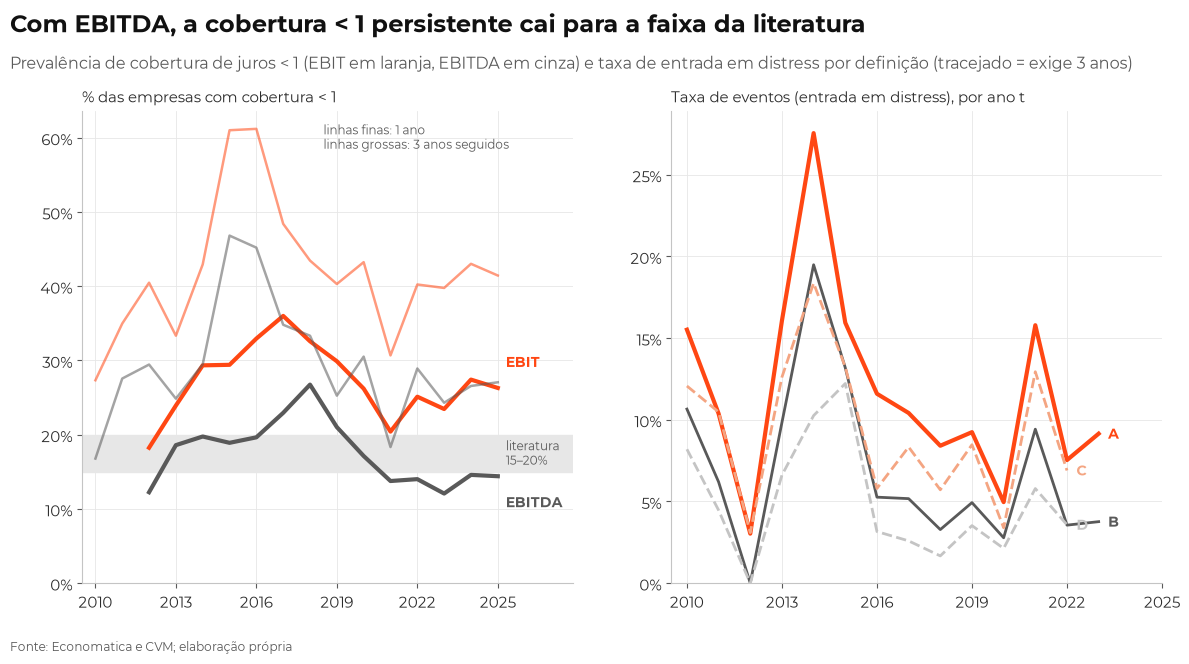

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
EBIT (A e C),"0,273","0,350","0,405","0,333","0,429","0,610","0,612","0,484","0,435","0,403","0,432","0,307","0,402","0,398","0,430","0,414"
EBITDA (B e D),"0,168","0,276","0,294","0,249","0,295","0,468","0,452","0,348","0,333","0,253","0,305","0,183","0,289","0,243","0,266","0,271"


In [4]:
prev = pd.DataFrame({'EBIT (A e C)': alvo.prevalencia_por_ano(ea, 'ebit'),
                     'EBITDA (B e D)': alvo.prevalencia_por_ano(ea, 'ebitda')})
taxa = pd.DataFrame({d: alvo.taxa_eventos_por_ano(ea, alvos[d]) for d in cfg.DEFINICOES_ALVO})

cores = {'A': cfg.COR_DESTAQUE, 'B': '#595959', 'C': '#F4A582', 'D': cfg.CINZA}
pers = pd.DataFrame({'EBIT (A e C)': alvo.prevalencia_persistente_por_ano(ea, 'ebit'),
                     'EBITDA (B e D)': alvo.prevalencia_persistente_por_ano(ea, 'ebitda')})
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=cfg.TAMANHO_FIG)
lo, hi = cfg.PREVALENCIA_REF
ax1.axhspan(lo, hi, color=cfg.CINZA_GRID, zorder=0)
ax1.text(prev.index[-1] + 0.3, (lo + hi) / 2, 'literatura' + chr(10) + '15–20%', fontsize=8.5, color=cfg.COR_SUBTITULO, va='center')
for col, cor, rot in [('EBIT (A e C)', cfg.COR_DESTAQUE, 'EBIT'), ('EBITDA (B e D)', '#595959', 'EBITDA')]:
    ax1.plot(prev.index, prev[col], color=cor, lw=1.8, alpha=0.55)
    ax1.plot(pers.index, pers[col], color=cor, lw=3)
    ax1.text(pers.index[-1] + 0.3, pers[col].iloc[-1] + (0.035 if rot == 'EBIT' else -0.035), rot, color=cor, fontsize=10, va='center', fontweight='bold')
ax1.annotate('linhas finas: 1 ano' + chr(10) + 'linhas grossas: 3 anos seguidos', (2018.5, 0.62), fontsize=8.5, color=cfg.COR_SUBTITULO, va='top')
ax1.set_xlim(prev.index[0] - 0.5, prev.index[-1] + 2.8)
ax1.set_title('% das empresas com cobertura < 1', fontsize=11, color=cfg.COR_EIXO, loc='left')
for d in cfg.DEFINICOES_ALVO:
    s_ = taxa[d].dropna()
    ax2.plot(s_.index, s_.values, color=cores[d], lw=3 if d == 'A' else 2, ls='-' if cfg.DEFINICOES_ALVO[d][1] == 2 else '--')
    ax2.text(s_.index[-1] + 0.3, s_.iloc[-1], d, color=cores[d], fontsize=10, va='center', fontweight='bold')
ax2.set_xlim(taxa.index[0] - 0.5, taxa.index[-1] + 1.5)
ax2.set_title('Taxa de eventos (entrada em distress), por ano t', fontsize=11, color=cfg.COR_EIXO, loc='left')
for ax in (ax1, ax2):
    ax.set_ylim(0, None)
    ax.yaxis.set_major_formatter(style.formatador(0, pct=True))
    ax.set_xticks(range(2010, 2026, 3))
style.titulos(fig, 'Com EBITDA, a cobertura < 1 persistente cai para a faixa da literatura',
              'Prevalência de cobertura de juros < 1 (EBIT em laranja, EBITDA em cinza) e taxa de entrada em distress por definição (tracejado = exige 3 anos)')
style.salvar(fig, 'fig16_sensibilidade_alvo')
plt.show()
prev.T

### 2b. Comparação justa com a literatura: cobertura < 1 por 3 anos seguidos

A referência de cerca de 15–17% do BIS não conta empresas com cobertura < 1 em **um** ano. Ela conta empresas com cobertura < 1 por **três anos seguidos** (além de um q de Tobin baixo, que não usamos). Para comparar maçã com maçã, calculamos a mesma persistência: a % das empresas com cobertura < 1 em t, t−1 e t−2, entre as classificáveis nos três anos.

In [5]:
pers = pd.DataFrame({'EBIT (A e C)': alvo.prevalencia_persistente_por_ano(ea, 'ebit'),
                     'EBITDA (B e D)': alvo.prevalencia_persistente_por_ano(ea, 'ebitda')})
comp = pd.DataFrame({'1 ano (média anual)': prev.mean(), '3 anos seguidos (média anual)': pers.mean(),
                     '3 anos seguidos: mín.': pers.min(), '3 anos seguidos: máx.': pers.max()})
display(comp.style.format(lambda x: style.pct_br(x, 1)))
pers.T.style.format(lambda x: style.pct_br(x, 0))

,1 ano (média anual),3 anos seguidos (média anual),3 anos seguidos: mín.,3 anos seguidos: máx.
EBIT (A e C),"42,0%","27,2%","18,2%","36,0%"
EBITDA (B e D),"29,3%","17,6%","12,1%","26,7%"


ano,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
EBIT (A e C),18%,24%,29%,29%,33%,36%,33%,30%,26%,20%,25%,23%,27%,26%
EBITDA (B e D),12%,19%,20%,19%,20%,23%,27%,21%,17%,14%,14%,12%,15%,14%


**Leitura.** Na medida comparável à da literatura, o **EBITDA fica dentro da faixa** (17,6% em média, entre 12% e 27% conforme o ano). O EBIT fica acima (27%, entre 18% e 36%). Ou seja, a despesa financeira bruta do Economatica não é o único problema. Grande parte do excesso vem de usar o **EBIT**, que penaliza empresas intensivas em capital por causa da depreciação.

## 3. Eventos reais de crédito

`data/raw/eventos/eventos_credito.csv` foi pré-preenchido com os casos indicados pela dupla, **todos com `conferido = não`**: as datas e os tickers precisam ser checados. Foram incluídas duas colunas extras, `empresa` e `obs`. Para cada evento, verificamos se a empresa estava em distress (cobertura < 1) no ano do evento, em t−1 e em t−2.

Legenda: `sim` / `não`; `n.c.` = não classificável (despesa financeira ≤ 0 ou ausente); `sem dado` = empresa fora da base naquele ano. A condição de distress só depende do numerador, então o status de A é igual ao de C, e o de B, igual ao de D.

In [6]:
ev = alvo.carregar_eventos()
display(ev)
st = {num: alvo.status_eventos(ea, ev, num) for num in ['ebit', 'ebitda']}
lado = st['ebit'][['ticker', 'tipo', 'ano_evento']].copy()
for num, rot in [('ebit', 'EBIT (A, C)'), ('ebitda', 'EBITDA (B, D)')]:
    for c in ['no ano', 't−1', 't−2']:
        lado[f'{rot} {c}'] = st[num][c]
lado

,ticker,empresa,data_evento,tipo,fonte,conferido,obs,ano_evento
0,AMER3,Americanas,2023-01-19,RJ,fato relevante / imprensa (a conferir),não,NaN,2023
1,OIBR3,Oi,2023-03-01,RJ,fato relevante / imprensa (a conferir),não,segunda RJ; a primeira foi em jun/2016 (CVM: e...,2023
2,LIGT3,Light,2023-05-12,RJ,fato relevante / imprensa (a conferir),não,NaN,2023
3,GOLL4,Gol,2024-01-25,Chapter 11,fato relevante / imprensa (a conferir),não,registro cancelado na CVM; Gol não está na bas...,2024
4,BHIA3,Casas Bahia,2024-04-28,RE,fato relevante / imprensa (a conferir),não,Economatica sem despesa financeira de 2015 a 2023,2024
5,AZUL3,Azul,2025-05-28,Chapter 11,fato relevante / imprensa (a conferir),não,ticker na B3 é AZUL4; na base do Economatica a...,2025
6,MBLY3,Mobly,NaT,a confirmar,a confirmar,não,tipo e data a confirmar; Mobly não está na bas...,<NA>
7,FASA3,Fasa,2026-04-17,RJ,CVM cad_cia_aberta (SIT_EMISSOR desde 2026-04-17),não,data de início da situação 'em recuperação jud...,2026


,ticker,tipo,ano_evento,"EBIT (A, C) no ano","EBIT (A, C) t−1","EBIT (A, C) t−2","EBITDA (B, D) no ano","EBITDA (B, D) t−1","EBITDA (B, D) t−2"
0,AMER3,RJ,2023,sim,sim,sim,sim,sim,não
1,OIBR3,RJ,2023,sem dado,sem dado,sem dado,sem dado,sem dado,sem dado
2,LIGT3,RJ,2023,não,sim,sim,não,sim,não
3,GOLL4,Chapter 11,2024,sem dado,sem dado,sem dado,sem dado,sem dado,sem dado
4,BHIA3,RE,2024,sim,n.c.,n.c.,sim,n.c.,n.c.
5,AZUL3,Chapter 11,2025,sim,sim,sim,não,sim,não
6,MBLY3,a confirmar,<NA>,sem dado,sem dado,sem dado,sem dado,sem dado,sem dado
7,FASA3,RJ,2026,sem dado,n.c.,sem dado,sem dado,n.c.,sem dado


**Leitura.** Dos 8 eventos da lista, **só 3 podem ser avaliados** (Americanas, Light e Azul):
- **Oi, Gol e Mobly não estão na base do Economatica.** A Gol teve o registro cancelado na CVM, outro exemplo do viés de sobrevivência. A Oi está ativa e em RJ desde 2016, mas não entrou no Screening.
- **Casas Bahia:** o Economatica não traz a despesa financeira de 2015 a 2023, então a empresa é "não classificável" justamente nos anos anteriores à RE.
- **Fasa:** sem despesa financeira em 2025 e sem balanço em 2024.

Os 3 avaliáveis estavam em distress em t−1 pelas duas medidas. Com EBIT, os três também estavam em t−2. Com EBITDA, nenhum dos três estava em t−2.

### 3b. Lista ampliada: empresas da base em recuperação judicial ou extrajudicial segundo a CVM

Com só 3 eventos avaliáveis, o critério 2 fica fraco. O cadastro da CVM informa a **situação do emissor** (`SIT_EMISSOR`) e a data em que ela começou. Isso permite uma lista ampliada de candidatos, **não conferida**: a data é o início da situação atual e pode não coincidir com o pedido. Ela **não foi adicionada ao CSV**; fica como sugestão para a dupla.

In [7]:
cad1 = dados.cad_por_cnpj(dados.carregar_cad_cvm())
ev_cvm = alvo.eventos_cvm(ea, cad1)
st_cvm = {num: alvo.status_eventos(ea, ev_cvm, num) for num in ['ebit', 'ebitda']}
lado_cvm = ev_cvm[['ticker', 'empresa', 'tipo', 'data_evento']].copy()
for num, rot in [('ebit', 'EBIT'), ('ebitda', 'EBITDA')]:
    for c in ['t−1', 't−2']:
        lado_cvm[f'{rot} {c}'] = st_cvm[num][c].to_numpy()
lado_cvm

,ticker,empresa,tipo,data_evento,EBIT t−1,EBIT t−2,EBITDA t−1,EBITDA t−2
0,INEP3,INEPAR S.A. INDUSTRIA E CONSTRUCOES EM RECUPER...,RJ,2014-09-15,sim,sim,sim,sim
1,LUPA3,LUPATECH S.A.,RJ,2015-12-11,sim,sim,sim,sim
2,BDLL4,BARDELLA S.A. INDUSTRIAS MECANICAS - EM RECUPE...,RJ,2019-08-07,sim,sim,sim,sim
3,JFEN3,JOAO FORTES ENGENHARIA SA - EM RECUPERAÇÃO JUD...,RJ,2020-05-11,sim,sim,sim,sim
4,CTAX3,CONTAX PARTICIPAÇÕES S.A. - EM RECUPERAÇÃO JUD...,RJ,2022-06-15,sim,sim,sim,sim
5,RSID3,ROSSI RESIDENCIAL S.A. - EM RECUPERAÇÃO JUDICIAL,RJ,2022-09-30,sim,sim,sim,sim
6,PMAM3,PARANAPANEMA S.A. - EM RECUPERAÇÃO JUDICIAL,RJ,2022-12-13,sim,sim,sim,sim
7,AMER3,AMERICANAS S.A. - EM RECUPERAÇÃO JUDICIAL,RJ,2023-01-19,sim,sim,sim,não
8,NEXP3,NEXPE PARTICIPAÇÕES S.A. - EM RECUPERAÇÃO JUDI...,RJ,2023-02-24,sim,sim,sim,sim
9,LIGT3,LIGHT S.A. - EM RECUPERAÇÃO JUDICIAL,RJ,2023-05-16,sim,sim,sim,não


In [8]:
def contagem(s):
    av = s[s['avaliável']]
    return pd.Series({'avaliáveis': len(av), 'sinalizados em t−1 ou t−2': int(av['sinaliza em t−1 ou t−2'].sum()),
                      'em distress em t−1': int((av['t−1'] == 'sim').sum()), 'em distress em t−2': int((av['t−2'] == 'sim').sum())})

sinal = pd.DataFrame({
    ('lista da dupla', 'EBIT (A, C)'): contagem(st['ebit']), ('lista da dupla', 'EBITDA (B, D)'): contagem(st['ebitda']),
    ('lista CVM', 'EBIT (A, C)'): contagem(st_cvm['ebit']), ('lista CVM', 'EBITDA (B, D)'): contagem(st_cvm['ebitda']),
})
sinal

lista da dupla                 lista CVM              
                             EBIT (A, C) EBITDA (B, D) EBIT (A, C) EBITDA (B, D)
avaliáveis                             3             3          15            15
sinalizados em t−1 ou t−2              3             3          14            14
em distress em t−1                     3             3          14            14
em distress em t−2                     3             0          12            10

**Leitura.** Na lista ampliada da CVM, as duas medidas sinalizam **14 dos 15 eventos avaliáveis em t−1**. A única exceção é a Nutriplant (RE em 2025), que tinha cobertura ≥ 1 nos dois anos anteriores pelas duas medidas. Em t−2, o EBIT sinaliza 12 e o EBITDA, 10. O EBITDA reage um pouco mais tarde (Americanas, Light e Azul só aparecem em t−1), mas a capacidade de sinalizar **até t−1 é a mesma**. Trocar EBIT por EBITDA reduz a prevalência sem perder eventos reais.

## 4. Comparação com o critério e recomendação

| critério | A (EBIT, 2 anos) | B (EBITDA, 2 anos) | C (EBIT, 3 anos) | D (EBITDA, 3 anos) |
|---|---|---|---|---|
| 1. prevalência, 1 ano (média) | 42% | 29% | 42% | 29% |
| 1. prevalência, 3 anos seguidos (comparável ao BIS) | 27% | **17,6%** ✔ | 27% | **17,6%** ✔ |
| 2. eventos sinalizados em t−1 ou t−2 (CVM / lista da dupla) | 14 de 15 / 3 de 3 | 14 de 15 / 3 de 3 | 14 de 15 / 3 de 3 | 14 de 15 / 3 de 3 |
| 3. eventos no treino / por parâmetro (13) | 115 / 8,8 | 82 / 6,3 | 87 / 6,7 | 54 / 4,2 ✘ |
| eventos validação / teste | 17 / 52 | 11 / 31 | 14 / 32 | 8 / 17 ✘ |

**Recomendação: definição B (EBITDA / despesa financeira < 1 em t+1 e t+2).**
- **Critério 1:** é a única, junto com a D, que fica na faixa da literatura quando medida do mesmo jeito (17,6% com 3 anos seguidos). Na medida de 1 ano, cai de 42% para 29%.
- **Critério 2:** sinaliza os mesmos eventos reais que a A em t−1 (14 de 15 na lista da CVM e 3 de 3 na lista da dupla).
- **Critério 3:** nenhuma definição atinge 10 eventos por parâmetro. A B fica em 6,3, contra 8,8 da A. Isso se resolve na modelagem de duas formas: (i) a logística com regularização L2, já prevista na Etapa D, e (ii) menos parâmetros, por exemplo 5 macrossetores (4 dummies) em vez de 6, que dariam 12 parâmetros e 6,8 eventos por parâmetro.
- **D descartada:** tem a mesma prevalência que a B, mas só 54 eventos no treino, 8 na validação e 17 no teste, poucos demais para escolher hiperparâmetros e avaliar.
- **Para a robustez (Etapa D, item 5b):** usar a **A**, que é a alternativa mais próxima (mesmo horizonte, só troca o numerador).

**Riscos da escolha B:**
- **A validação fica com só 11 eventos**, e escolher o limiar e os hiperparâmetros com 11 eventos é instável. Sugestão: escolher os hiperparâmetros por validação temporal expandindo dentro do treino + validação (2010–2020), sempre sem tocar no teste.
- O EBITDA ignora a necessidade de repor ativos. Uma empresa com EBITDA que cobre os juros, mas EBIT que não cobre, também pode estar em dificuldade. Esses casos deixam de ser eventos.

**A escolha é da dupla.**